# **Advanced Data Analysis and Visualization in Logistics**

## **1. Load and validate the dataset**

### **1.1 Load the Dataset**

The cleaned logistics dataset is loaded using Pandas for further analysis.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/cleaned_logistics_dataset (1).csv")

print("Dataset loaded successfully.")


Dataset loaded successfully.


### **1.2 Data Validation**
The dataset structure, data types, missing values, and duplicate records are examined to assess data quality.

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())


Dataset shape: (45593, 20)

Column names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Data types:
ID                              object
Delivery_person_ID              object
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weatherconditions               object
Road_traffic_density            object
Vehicle_condition                int6

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,1900-01-01 11:30:00,1900-01-01 11:45:00,conditions Sunny,High,2,Snack,motorcycle,0.0,No,Urban,24
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,1900-01-01 19:45:00,1900-01-01 19:50:00,conditions Stormy,Jam,2,Snack,scooter,1.0,No,Metropolitian,33
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,1900-01-01 08:30:00,1900-01-01 08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Urban,26
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,1900-01-01 18:00:00,1900-01-01 18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,21
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,1900-01-01 13:30:00,1900-01-01 13:45:00,conditions Cloudy,High,1,Snack,scooter,1.0,No,Metropolitian,30


### **1.3 Descriptive Statistics**
Descriptive statistics summarize the central tendency, variability, and distribution of numerical variables.

In [5]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,45593.0,29.584739,5.696333,15.000000,25.000000,30.000000,34.000000,50.000000
Delivery_person_Ratings,45593.0,4.635040,0.324598,1.000000,4.600000,4.700000,4.800000,5.000000
Restaurant_latitude,45593.0,17.017729,8.185109,-30.905562,12.933284,18.546947,22.728163,30.914057
Restaurant_longitude,45593.0,70.231332,22.883647,-88.366217,73.170000,75.898497,78.044095,88.433452
Delivery_location_latitude,45593.0,17.465186,7.335122,0.010000,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45593.0,70.845702,21.118812,0.010000,73.280000,76.002574,78.107044,88.563452
Vehicle_condition,45593.0,1.023359,0.839065,0.000000,0.000000,1.000000,2.000000,3.000000
multiple_deliveries,45593.0,0.750225,0.567430,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken(min),45593.0,26.294607,9.383806,10.000000,19.000000,26.000000,32.000000,54.000000


## **2. Data Quality and Variable Verification**

### **2.1 Verify Numerical Data Types**
The data types and unique values of key logistics variables are examined to identify formatting inconsistencies.

In [6]:
columns_to_check = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken(min)"
]

for col in columns_to_check:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print("Unique values:", df[col].nunique())
        print("Sample values:", df[col].dropna().unique()[:10])



Delivery_person_Age
Data type: float64
Unique values: 22
Sample values: [37. 34. 23. 38. 32. 22. 33. 35. 36. 21.]

Delivery_person_Ratings
Data type: float64
Unique values: 27
Sample values: [4.9 4.5 4.4 4.7 4.6 4.8 4.2 4.3 4.  4.1]

Vehicle_condition
Data type: int64
Unique values: 4
Sample values: [2 0 1 3]

multiple_deliveries
Data type: float64
Unique values: 4
Sample values: [0. 1. 3. 2.]

Time_taken(min)
Data type: int64
Unique values: 45
Sample values: [24 33 26 21 30 40 32 34 46 23]


### **2.2 Check Numerical Value Ranges**
The minimum, maximum, and distinct values of key numerical variables are reviewed to identify potential anomalies.

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numeric_columns.tolist())

display(df[numeric_columns].agg(["min", "max"]).T)


Numerical columns:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Vehicle_condition', 'multiple_deliveries', 'Time_taken(min)']


,min,max
Delivery_person_Age,15.000000,50.000000
Delivery_person_Ratings,1.000000,5.000000
Restaurant_latitude,-30.905562,30.914057
Restaurant_longitude,-88.366217,88.433452
Delivery_location_latitude,0.010000,31.054057
Delivery_location_longitude,0.010000,88.563452
Vehicle_condition,0.000000,3.000000
multiple_deliveries,0.000000,3.000000
Time_taken(min),10.000000,54.000000


## **3. Logistics Performance Analysis**

### **3.1 Delivery Performance KPIs**
Key delivery performance metrics are calculated to summarize delivery time, customer ratings, and delivery-person age.

In [8]:
# Calculate key performance metrics
kpis = {
    "Total Delivery Records": len(df),
    "Average Delivery Time (min)": df["Time_taken(min)"].mean(),
    "Median Delivery Time (min)": df["Time_taken(min)"].median(),
    "Minimum Delivery Time (min)": df["Time_taken(min)"].min(),
    "Maximum Delivery Time (min)": df["Time_taken(min)"].max(),
    "Average Delivery Rating": df["Delivery_person_Ratings"].mean(),
    "Average Delivery Person Age": df["Delivery_person_Age"].mean()
}

for metric, value in kpis.items():
    print(f"{metric}: {value:.2f}" if isinstance(value, (int, float)) else f"{metric}: {value}")


Total Delivery Records: 45593.00
Average Delivery Time (min): 26.29
Median Delivery Time (min): 26.00
Minimum Delivery Time (min): 10.00
Maximum Delivery Time (min): 54.00
Average Delivery Rating: 4.64
Average Delivery Person Age: 29.58


###**3.2 Delivery Time Distribution**
The distribution of delivery times is visualized to identify common delivery durations, spread, and potential extreme values.

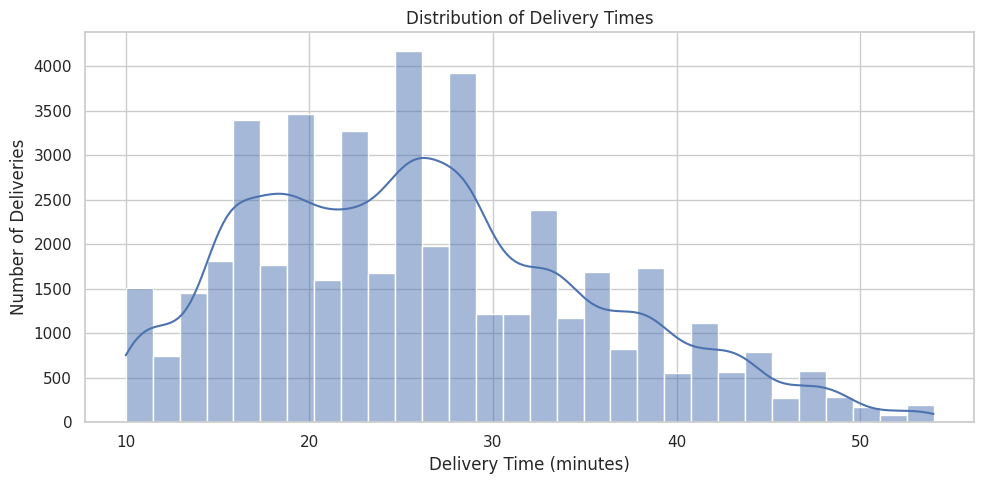

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Time_taken(min)", bins=30, kde=True)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()


### **3.3 Delivery Time by Road Traffic Density**
Delivery times are compared across different road traffic conditions to identify their impact on logistics performance.

,count,mean,median,min,max
Road_traffic_density,,,,,
High,4425,27.24,27.0,10,54
Jam,14143,31.18,31.0,10,54
Low,15477,21.27,20.0,10,44
Medium,10947,26.70,27.0,10,49
Unknown,601,26.54,26.0,10,54


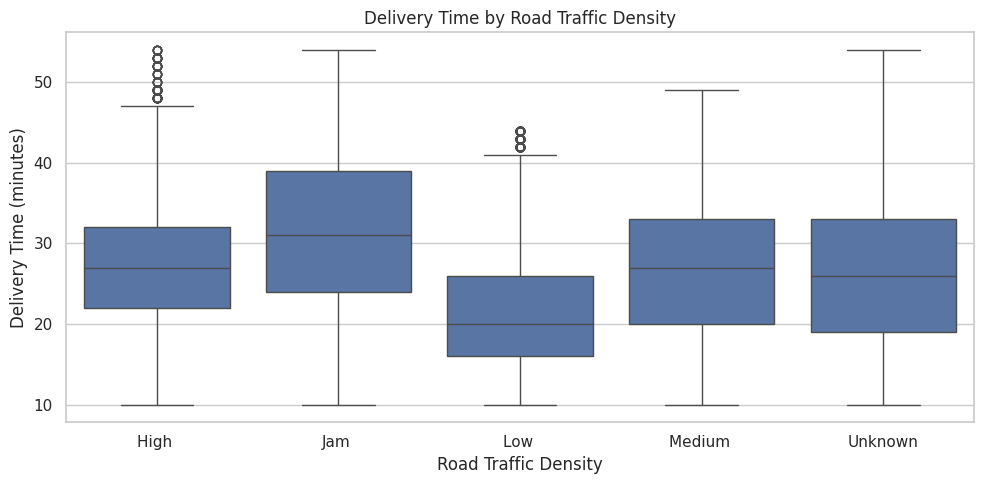

In [29]:
# Analyze delivery time by road traffic density

traffic_summary = df.groupby("Road_traffic_density")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(traffic_summary)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Road_traffic_density", y="Time_taken(min)")

plt.title("Delivery Time by Road Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.4 Delivery Time by Weather Conditions**
Delivery times are analyzed across different weather conditions to understand their relationship with logistics performance.

,count,mean,median,min,max
Weatherconditions,,,,,
conditions Cloudy,7536,28.92,28.0,10,54
conditions Fog,7654,28.92,28.0,10,54
conditions NaN,616,26.55,26.0,10,54
conditions Sandstorms,7495,25.88,26.0,10,54
conditions Stormy,7586,25.87,26.0,10,54
conditions Sunny,7284,21.86,20.0,10,54
conditions Windy,7422,26.12,26.0,10,54


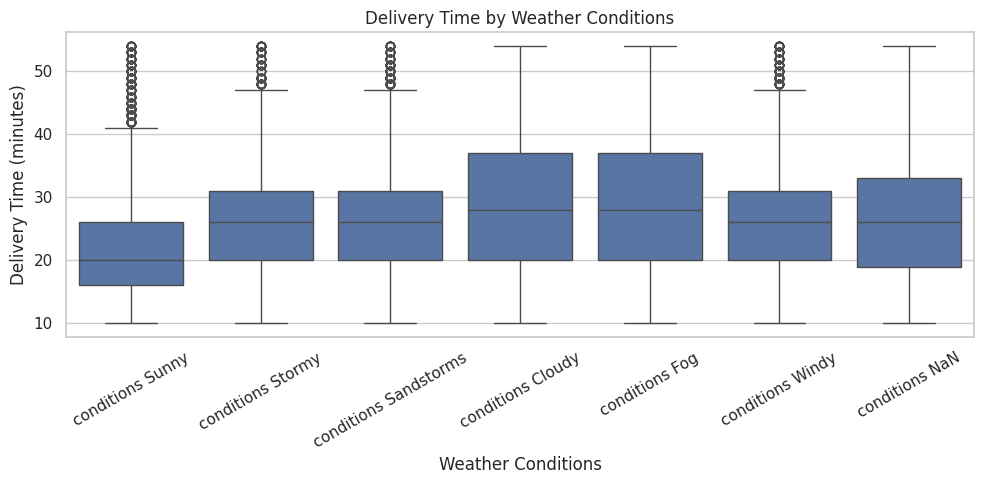

In [11]:
weather_summary = df.groupby("Weatherconditions")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(weather_summary)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Weatherconditions", y="Time_taken(min)")

plt.title("Delivery Time by Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Delivery Time (minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### **3.5 Delivery Time by Vehicle Condition**
Delivery times are compared across vehicle conditions to examine their relationship with delivery performance.

,count,mean,median,min,max
Vehicle_condition,,,,,
0,15009,30.07,28.0,10,54
1,15030,24.36,24.0,10,49
2,15034,24.46,24.0,10,49
3,520,26.49,26.0,10,54


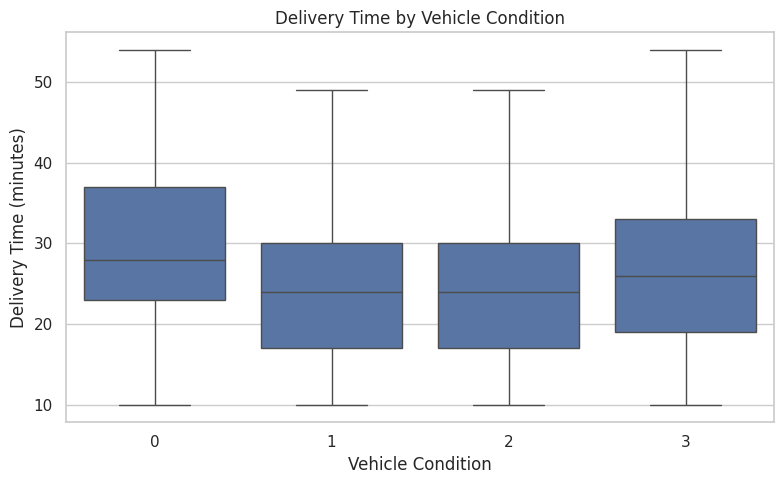

In [12]:
vehicle_summary = df.groupby("Vehicle_condition")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(vehicle_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Vehicle_condition", y="Time_taken(min)")

plt.title("Delivery Time by Vehicle Condition")
plt.xlabel("Vehicle Condition")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.6 Delivery Time by City**
Delivery times are compared across city categories to identify differences in logistics performance.

,count,mean,median,min,max
City,,,,,
Metropolitian,34093,27.32,27.0,10,54
NaN,1200,22.06,21.0,10,54
Semi-Urban,164,49.73,49.0,44,54
Urban,10136,22.98,22.0,10,54


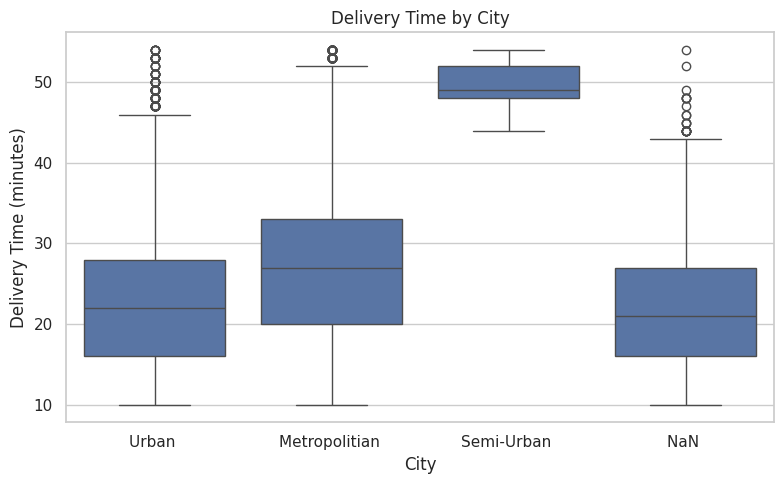

In [13]:
city_summary = df.groupby("City")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(city_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="City", y="Time_taken(min)")

plt.title("Delivery Time by City")
plt.xlabel("City")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.7 Delivery Time by Type of Order**
Delivery times are compared across order types to identify differences in delivery performance.

,count,mean,median,min,max
Type_of_order,,,,,
Buffet,11280,26.28,26.0,10,54
Drinks,11322,26.19,25.0,10,54
Meal,11458,26.42,26.0,10,54
Snack,11533,26.29,26.0,10,54


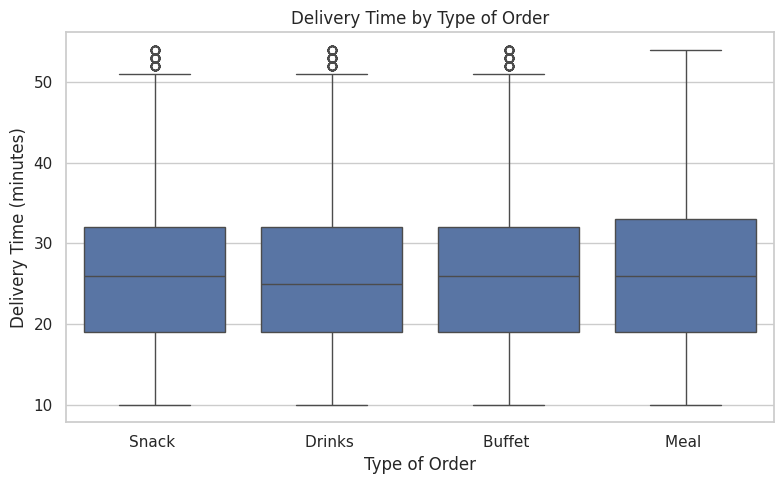

In [14]:
order_summary = df.groupby("Type_of_order")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(order_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Type_of_order", y="Time_taken(min)")

plt.title("Delivery Time by Type of Order")
plt.xlabel("Type of Order")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.8 Delivery Time by Type of Vehicle**
Delivery times are compared across vehicle types to examine differences in delivery performance.

,count,mean,median,min,max
Type_of_vehicle,,,,,
bicycle,68,26.43,26.0,10,47
electric_scooter,3814,24.47,24.0,10,53
motorcycle,26435,27.61,26.0,10,54
scooter,15276,24.48,24.0,10,54


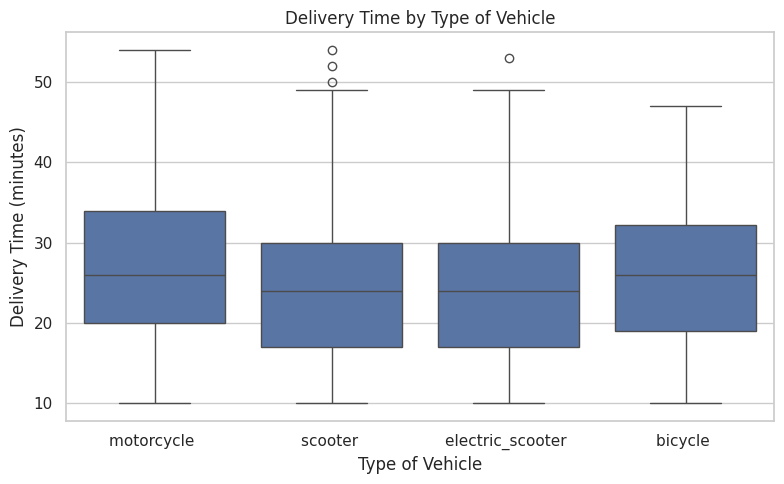

In [15]:
vehicle_type_summary = df.groupby("Type_of_vehicle")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(vehicle_type_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Type_of_vehicle", y="Time_taken(min)")

plt.title("Delivery Time by Type of Vehicle")
plt.xlabel("Type of Vehicle")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.9 Delivery Time by Number of Multiple Deliveries**
Delivery times are analyzed by the number of deliveries handled together to examine their relationship with delivery duration.

,count,mean,median,min,max
multiple_deliveries,,,,,
0.0,14095,22.88,22.0,10,54
1.0,29152,26.72,26.0,10,54
2.0,1985,40.45,40.0,31,54
3.0,361,47.82,48.0,42,54


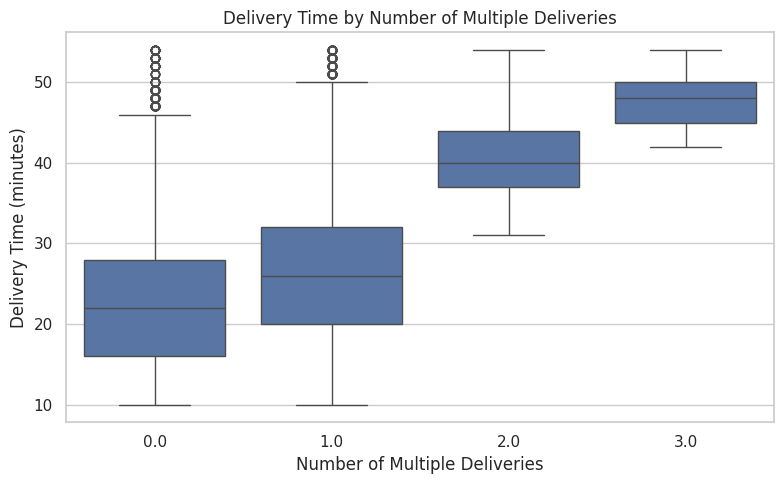

In [16]:
multiple_delivery_summary = df.groupby("multiple_deliveries")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(multiple_delivery_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="multiple_deliveries", y="Time_taken(min)")

plt.title("Delivery Time by Number of Multiple Deliveries")
plt.xlabel("Number of Multiple Deliveries")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.10 Delivery Time by Festival Status**
Delivery times are compared by festival status to examine whether festival periods are associated with changes in delivery duration.

,count,mean,median,min,max
Festival,,,,,
NaN,228,11.17,11.0,10,14
No,44469,25.98,25.0,10,54
Yes,896,45.52,45.0,38,54


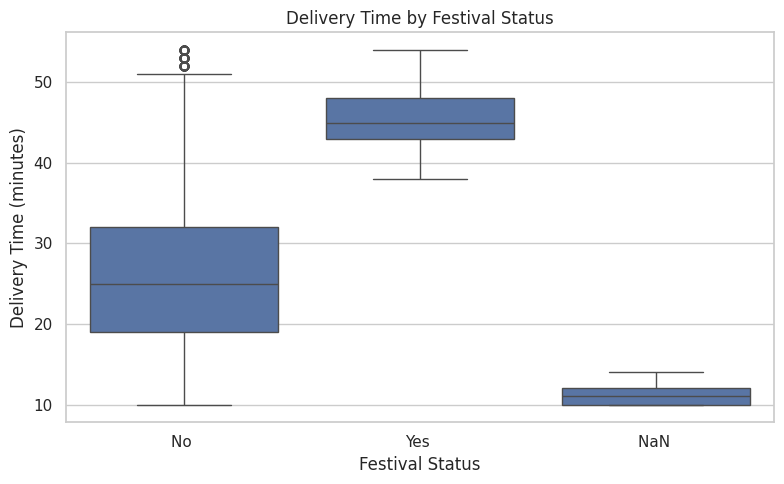

In [18]:
festival_summary = df.groupby("Festival")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(festival_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Festival", y="Time_taken(min)")

plt.title("Delivery Time by Festival Status")
plt.xlabel("Festival Status")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.11 Delivery Time by Delivery Person Ratings**
Delivery times are analyzed across customer rating levels to examine the relationship between delivery duration and customer satisfaction.

,count,mean,median,min,max
Delivery_person_Ratings,,,,,
1.0,38,26.00,26.5,13,44
2.5,20,37.30,35.5,31,44
2.6,22,38.59,39.0,31,44
2.7,22,35.86,36.5,31,43
2.8,19,36.63,37.0,31,43
2.9,19,38.53,39.0,31,44
3.0,6,32.67,32.5,31,34
3.1,29,36.55,35.0,31,44
3.2,29,36.34,36.0,31,44


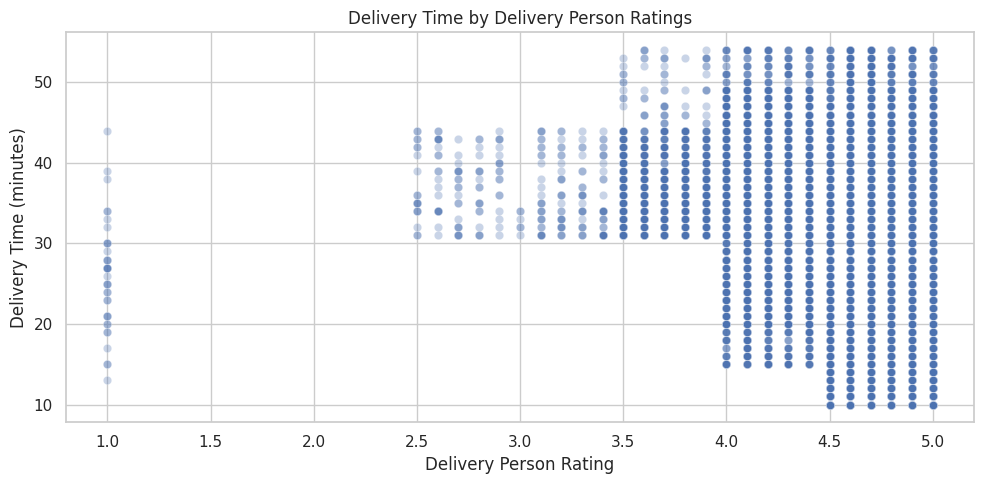

In [19]:
rating_summary = df.groupby("Delivery_person_Ratings")["Time_taken(min)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(rating_summary)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="Delivery_person_Ratings",
    y="Time_taken(min)",
    alpha=0.3
)

plt.title("Delivery Time by Delivery Person Ratings")
plt.xlabel("Delivery Person Rating")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

### **3.12 Correlation Analysis of Numerical Variables**
A correlation matrix is used to examine relationships among numerical logistics variables and identify factors associated with delivery time.

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
Delivery_person_Age,1.00,-0.08,-0.01,-0.01,0.00,-0.00,0.00,0.11,0.29
Delivery_person_Ratings,-0.08,1.00,-0.00,-0.00,-0.01,-0.01,0.03,-0.11,-0.33
Restaurant_latitude,-0.01,-0.00,1.00,0.66,0.87,0.60,-0.03,0.01,0.01
Restaurant_longitude,-0.01,-0.00,0.66,1.00,0.63,0.92,-0.04,0.00,0.01
Delivery_location_latitude,0.00,-0.01,0.87,0.63,1.00,0.69,-0.00,0.01,0.01
Delivery_location_longitude,-0.00,-0.01,0.60,0.92,0.69,1.00,-0.00,0.00,0.01
Vehicle_condition,0.00,0.03,-0.03,-0.04,-0.00,-0.00,1.00,-0.10,-0.23
multiple_deliveries,0.11,-0.11,0.01,0.00,0.01,0.00,-0.10,1.00,0.38
Time_taken(min),0.29,-0.33,0.01,0.01,0.01,0.01,-0.23,0.38,1.00


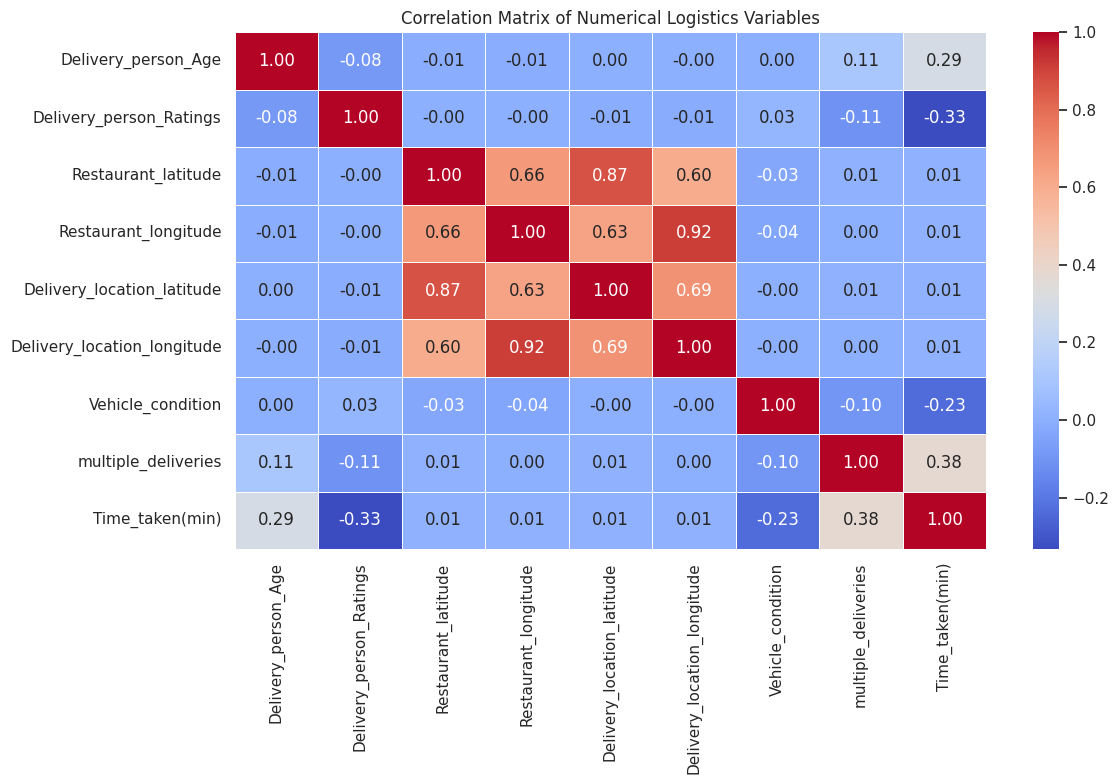

In [20]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Logistics Variables")
plt.tight_layout()
plt.show()

## **4. Key Analytical Insights**

### **4. Key Analytical Insights**
The results of exploratory data analysis are interpreted to identify delivery delays, operational bottlenecks, and factors associated with logistics performance.

In [21]:
print("KEY LOGISTICS PERFORMANCE INSIGHTS")
print("-" * 45)

print(f"Average delivery time: {df['Time_taken(min)'].mean():.2f} minutes")
print(f"Median delivery time: {df['Time_taken(min)'].median():.2f} minutes")

traffic_means = df.groupby("Road_traffic_density")["Time_taken(min)"].mean()
print(f"Longest average delivery time by traffic: {traffic_means.idxmax()} "
      f"({traffic_means.max():.2f} minutes)")

multiple_means = df.groupby("multiple_deliveries")["Time_taken(min)"].mean()
print(f"Longest average delivery time by multiple deliveries: "
      f"{multiple_means.idxmax():.0f} deliveries "
      f"({multiple_means.max():.2f} minutes)")

festival_means = df.groupby("Festival")["Time_taken(min)"].mean()
if "Yes" in festival_means.index and "No" in festival_means.index:
    print(f"Average delivery time during festivals: "
          f"{festival_means['Yes']:.2f} minutes")
    print(f"Average delivery time without festivals: "
          f"{festival_means['No']:.2f} minutes")

print("\nCorrelation with delivery time:")
print(correlation_matrix["Time_taken(min)"].sort_values(ascending=False).round(2))


KEY LOGISTICS PERFORMANCE INSIGHTS
---------------------------------------------
Average delivery time: 26.29 minutes
Median delivery time: 26.00 minutes
Longest average delivery time by traffic: Jam  (31.18 minutes)
Longest average delivery time by multiple deliveries: 3 deliveries (47.82 minutes)

Correlation with delivery time:
Time_taken(min)                1.00
multiple_deliveries            0.38
Delivery_person_Age            0.29
Delivery_location_latitude     0.01
Restaurant_latitude            0.01
Restaurant_longitude           0.01
Delivery_location_longitude    0.01
Vehicle_condition             -0.23
Delivery_person_Ratings       -0.33
Name: Time_taken(min), dtype: float64


### **4.2 Interpretation of Key Findings**
The key findings are interpreted to identify potential causes of delivery delays and opportunities to improve logistics efficiency.

In [23]:
insights = pd.DataFrame({
    "Factor": [
        "Road Traffic Density",
        "Multiple Deliveries",
        "Delivery Person Age",
        "Delivery Person Ratings",
        "Vehicle Condition"
    ],
    "Finding": [
        "Jam traffic has the highest average delivery time (31.18 minutes).",
        "Three multiple deliveries have the highest average time (47.82 minutes).",
        "Age has a positive correlation (0.29) with delivery time.",
        "Ratings have a negative correlation (-0.33) with delivery time.",
        "Vehicle condition has a negative correlation (-0.23) with delivery time."
    ],
    "Operational Implication": [
        "Traffic-aware routing and delivery-time estimates may help manage delays.",
        "Review batching limits and delivery sequence for multiple orders.",
        "Investigate other factors before drawing conclusions about age.",
        "Explore whether delivery time and ratings vary together; correlation does not prove causation.",
        "Verify vehicle-condition coding before making maintenance recommendations."
    ]
})

display(insights.style.hide(axis="index"))


Factor,Finding,Operational Implication
Road Traffic Density,Jam traffic has the highest average delivery time (31.18 minutes).,Traffic-aware routing and delivery-time estimates may help manage delays.
Multiple Deliveries,Three multiple deliveries have the highest average time (47.82 minutes).,Review batching limits and delivery sequence for multiple orders.
Delivery Person Age,Age has a positive correlation (0.29) with delivery time.,Investigate other factors before drawing conclusions about age.
Delivery Person Ratings,Ratings have a negative correlation (-0.33) with delivery time.,Explore whether delivery time and ratings vary together; correlation does not prove causation.
Vehicle Condition,Vehicle condition has a negative correlation (-0.23) with delivery time.,Verify vehicle-condition coding before making maintenance recommendations.


## **5. Recommendations and Conclusion**

### **5.1 Recommendations for Improving Logistics Performance**

The findings suggest practical ways to reduce delivery delays, improve delivery planning, and monitor operational performance.

In [24]:
recommendations = pd.DataFrame({
    "Area": [
        "Road Traffic",
        "Multiple Deliveries",
        "Festival Demand",
        "Weather Conditions",
        "Data Quality"
    ],
    "Recommendation": [
        "Use traffic-aware routes and realistic delivery-time estimates.",
        "Review delivery batching and order sequences to reduce delays.",
        "Plan rider availability and delivery capacity during festivals.",
        "Monitor delivery performance under different weather conditions.",
        "Validate missing values and category codes before making decisions."
    ]
})

display(recommendations.style.hide(axis="index"))

Area,Recommendation
Road Traffic,Use traffic-aware routes and realistic delivery-time estimates.
Multiple Deliveries,Review delivery batching and order sequences to reduce delays.
Festival Demand,Plan rider availability and delivery capacity during festivals.
Weather Conditions,Monitor delivery performance under different weather conditions.
Data Quality,Validate missing values and category codes before making decisions.


### **5.2 Conclusion**

The exploratory data analysis examined delivery times and their relationships with traffic density, weather conditions, vehicle condition, order type, multiple deliveries, and delivery-person ratings. The average delivery time was 26.29 minutes, while deliveries during jam traffic averaged 31.18 minutes. Deliveries involving three multiple orders averaged 47.82 minutes. These findings highlight areas for further investigation and operational improvement. The results show associations, not proof of causation. Transportation costs and shipment volumes were not available in the dataset, so they could not be analyzed.

In [25]:
# Final data-quality validation

print("DATA QUALITY VALIDATION")
print("-" * 40)

print("\nDataset shape:", df.shape)

print("\nActual missing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nText placeholders in object columns:")
for col in df.select_dtypes(include="object").columns:
    placeholders = df[col].astype(str).str.strip().str.lower().isin(
        ["nan", "null", "none", ""]
    ).sum()
    if placeholders > 0:
        print(f"{col}: {placeholders}")

print("\nVehicle condition values:")
print(sorted(df["Vehicle_condition"].dropna().unique()))

print("\nFestival values:")
print(df["Festival"].value_counts(dropna=False))

print("\nDuplicate rows:", df.duplicated().sum())

DATA QUALITY VALIDATION
----------------------------------------

Dataset shape: (45593, 20)

Actual missing values:


,0



Text placeholders in object columns:
Road_traffic_density: 601
Festival: 228
City: 1200

Vehicle condition values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Festival values:
Festival
No      44469
Yes       896
NaN       228
Name: count, dtype: int64

Duplicate rows: 0


In [26]:
# Convert text placeholders to actual missing values

placeholder_values = ["nan", "null", "none", ""]

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda value: np.nan
        if isinstance(value, str)
        and value.strip().lower() in placeholder_values
        else value
    )

print("Missing values after standardization:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Missing values after standardization:


,0
Road_traffic_density,601
Festival,228
City,1200



Dataset shape: (45593, 20)
Duplicate rows: 0


In [27]:
# Handle missing categorical values for analysis

categorical_columns = [
    "Road_traffic_density",
    "Festival",
    "City"
]

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

print("Missing values in selected columns after handling:")
display(df[categorical_columns].isnull().sum())

print("\nDataset shape after handling:", df.shape)

Missing values in selected columns after handling:


,0
Road_traffic_density,0
Festival,0
City,0



Dataset shape after handling: (45593, 20)


In [30]:
# Final dataset validation

print("FINAL DATASET VALIDATION")
print("-" * 40)

print(f"Total records: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\nDelivery time summary:")
display(df["Time_taken(min)"].describe().round(2).to_frame())

print("\nDelivery time by festival status:")
display(
    df.groupby("Festival")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
)

FINAL DATASET VALIDATION
----------------------------------------
Total records: 45593
Total columns: 20
Total missing values: 0
Duplicate rows: 0

Delivery time summary:


,Time_taken(min)
count,45593.00
mean,26.29
std,9.38
min,10.00
25%,19.00
50%,26.00
75%,32.00
max,54.00



Delivery time by festival status:


,count,mean,median
Festival,,,
No,44469,25.98,25.0
Unknown,228,11.17,11.0
Yes,896,45.52,45.0
